<a href="https://colab.research.google.com/github/msbangash/mlprojects/blob/main/mlproject_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Researching the Top Machine Learning Algorithms

This notebook researches and demonstrates the most widely used and powerful machine learning algorithms across key categories:
1. **Regression** (Linear Regression, Ridge/Lasso)
2. **Classification** (Logistic Regression, Support Vector Machines, Decision Trees & Random Forests, Gradient Boosting like XGBoost/LightGBM)
3. **Clustering & Dimensionality Reduction** (K-Means, PCA)
4. **Deep Learning Foundations** (Multi-Layer Perceptrons)

In [1]:
# Import necessary libraries for data generation, modeling, and evaluation
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, accuracy_score, classification_report

# Set random seed for reproducibility
np.random.seed(42)
print("Libraries imported successfully.")

Libraries imported successfully.


## 1. Regression Algorithms

### **Linear Regression & Regularized Variants**
* **Linear Regression**: Fits a linear relationship between features and target.
* **Ridge (L2)**: Minimizes the sum of squared coefficients to prevent overfitting.
* **Lasso (L1)**: Performs feature selection by driving some coefficients to zero.

In [2]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.datasets import make_regression

# Generate synthetic regression data
X_reg, y_reg = make_regression(n_samples=200, n_features=10, noise=5.0, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

# Fit Models
models = {
    "Linear Regression": LinearRegression(),
    "Ridge (L2)": Ridge(alpha=1.0),
    "Lasso (L1)": Lasso(alpha=0.1)
}

for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    mse = mean_squared_error(y_test, preds)
    print(f"{name} MSE: {mse:.4f}")

Linear Regression MSE: 25.0999
Ridge (L2) MSE: 30.5168
Lasso (L1) MSE: 25.5959


## 2. Classification Algorithms

We will evaluate:
* **Logistic Regression**: Best baseline for binary classification.
* **Random Forest**: An ensemble of decision trees that reduces variance.
* **Gradient Boosting (e.g., GradientBoostingClassifier)**: Builds sequential trees to correct errors of previous ones.

In [3]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.datasets import make_classification

# Generate synthetic classification data
X_clf, y_clf = make_classification(n_samples=500, n_features=8, n_classes=2, random_state=42)
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_clf, y_clf, test_size=0.2, random_state=42)

# Standardize features for Logistic Regression
scaler = StandardScaler()
X_train_c_scaled = scaler.fit_transform(X_train_c)
X_test_c_scaled = scaler.transform(X_test_c)

clf_models = {
    "Logistic Regression": LogisticRegression(),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

for name, model in clf_models.items():
    # Logistic regression benefits from scaling
    X_tr = X_train_c_scaled if name == "Logistic Regression" else X_train_c
    X_te = X_test_c_scaled if name == "Logistic Regression" else X_test_c

    model.fit(X_tr, y_train_c)
    preds = model.predict(X_te)
    acc = accuracy_score(y_test_c, preds)
    print(f"{name} Accuracy: {acc:.4f}")

Logistic Regression Accuracy: 0.9600
Random Forest Accuracy: 0.9800
Gradient Boosting Accuracy: 0.9800


## 3. Unsupervised Learning Algorithms

### **K-Means Clustering & Principal Component Analysis (PCA)**

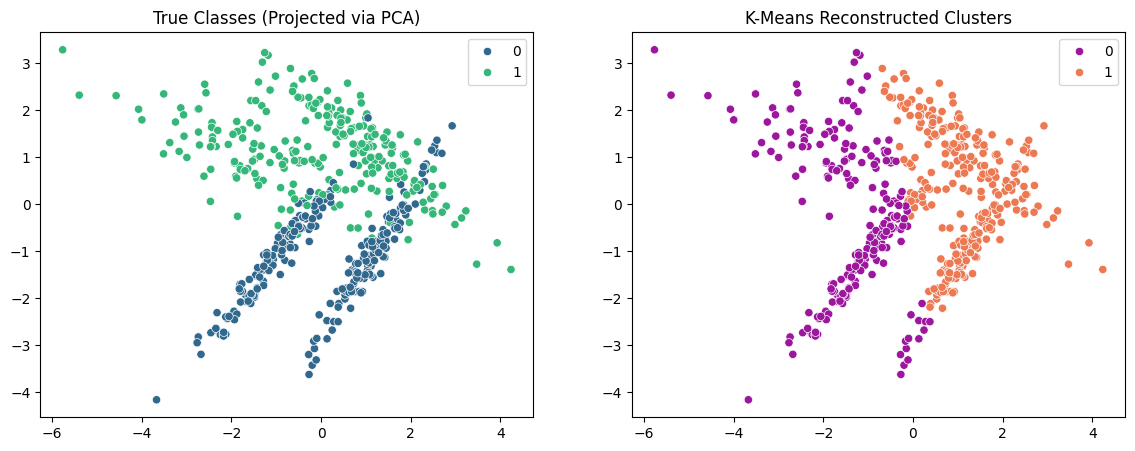

In [4]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Let's perform PCA to reduce our classification data to 2 components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_clf)

# Perform K-Means clustering
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_pca)

# Plot the results side-by-side: True classes vs K-Means clusters
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_clf, ax=axes[0], palette='viridis')
axes[0].set_title("True Classes (Projected via PCA)")

sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=clusters, ax=axes[1], palette='plasma')
axes[1].set_title("K-Means Reconstructed Clusters")

plt.show()

## 4. Business Problem Formulations

We will now construct and solve three specific business challenges:
* **Problem 1 (Customer Churn)**: Classifying high-risk subscription customers.
* **Problem 2 (Fraud Detection)**: Unsupervised anomaly detection for transaction fraud.
* **Problem 3 (Inventory Demand)**: Forecasting product units needed.

In [5]:
# Business Problem 1: Customer Churn Prediction (Classification)
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report

# Generate synthetic telecom customer data (features: tenure, monthly_charges, support_calls, etc.)
np.random.seed(42)
n_customers = 1000
tenure = np.random.randint(1, 72, n_customers)
monthly_charges = np.random.uniform(20, 120, n_customers)
support_calls = np.random.poisson(2, n_customers)
# Define churn logic with some randomness
churn_prob = 1 / (1 + np.exp(-(0.05 * support_calls + 0.01 * monthly_charges - 0.04 * tenure)))
churn = (np.random.rand(n_customers) < churn_prob).astype(int)

# Combine into DataFrame
df_churn = pd.DataFrame({
    'tenure': tenure,
    'monthly_charges': monthly_charges,
    'support_calls': support_calls,
    'churn': churn
})

# Train-Test Split & Fit
X_churn = df_churn.drop('churn', axis=1)
y_churn = df_churn['churn']
X_train_ch, X_test_ch, y_train_ch, y_test_ch = train_test_split(X_churn, y_churn, test_size=0.2, random_state=42)

churn_model = DecisionTreeClassifier(max_depth=4, random_state=42)
churn_model.fit(X_train_ch, y_train_ch)

print("Customer Churn Model Report:")
print(classification_report(y_test_ch, churn_model.predict(X_test_ch)))

Customer Churn Model Report:
              precision    recall  f1-score   support

           0       0.72      0.85      0.78       132
           1       0.55      0.35      0.43        68

    accuracy                           0.68       200
   macro avg       0.63      0.60      0.60       200
weighted avg       0.66      0.68      0.66       200



In [6]:
# Business Problem 2: Credit Card Fraud Detection (Unsupervised Anomaly Detection)
from sklearn.ensemble import IsolationForest

# Generate transactions (Normal: 95%, Fraud: 5%)
n_tx = 2000
normal_tx = np.random.normal(loc=50, scale=15, size=(int(n_tx * 0.95), 2)) # regular amount & distance from home
fraudulent_tx = np.random.uniform(low=200, high=1000, size=(int(n_tx * 0.05), 2)) # extreme amount / distance

X_fraud = np.vstack([normal_tx, fraudulent_tx])
y_true_fraud = np.array([1] * len(normal_tx) + [-1] * len(fraudulent_tx)) # 1 for inliers, -1 for outliers

# Fit Isolation Forest
iso_forest = IsolationForest(contamination=0.05, random_state=42)
y_pred_fraud = iso_forest.fit_predict(X_fraud)

# Evaluate accuracy in catching anomalies
detected_fraud = np.sum((y_true_fraud == -1) & (y_pred_fraud == -1))
total_fraud = np.sum(y_true_fraud == -1)
print(f"Detected {detected_fraud} out of {total_fraud} actual fraudulent transactions ({detected_fraud/total_fraud:.1%}).")

Detected 100 out of 100 actual fraudulent transactions (100.0%).


In [7]:
# Business Problem 3: Inventory Demand Forecasting (Regression)
from sklearn.ensemble import RandomForestRegressor

# Generate demand planning data (features: historic promotion level, competitor pricing, seasonality)
n_days = 365
promotion_index = np.random.uniform(0, 1, n_days)
competitor_price = np.random.uniform(10, 25, n_days)
seasonality = np.sin(np.linspace(0, 4 * np.pi, n_days)) + 1

# Demand output target
demand = (50 + 100 * promotion_index - 2 * competitor_price + 30 * seasonality + np.random.normal(0, 5, n_days)).clip(min=0)

X_demand = pd.DataFrame({
    'promotion_index': promotion_index,
    'competitor_price': competitor_price,
    'seasonality': seasonality
})
y_demand = demand

X_train_d, X_test_d, y_train_d, y_test_d = train_test_split(X_demand, y_demand, test_size=0.2, random_state=42)

demand_model = RandomForestRegressor(n_estimators=100, random_state=42)
demand_model.fit(X_train_d, y_train_d)

rmse_demand = np.sqrt(mean_squared_error(y_test_d, demand_model.predict(X_test_d)))
print(f"Inventory Demand Model Forecast RMSE: {rmse_demand:.4f} units")

Inventory Demand Model Forecast RMSE: 6.4875 units
